# Exploratory Data Analysis

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings

warnings.filterwarnings("ignore")

%reload_ext jupyter_black
%matplotlib inline

In [2]:
from data_profiling import ProfileReport

In [3]:
from pathlib import Path

data_path = Path("../data/raw/Telco-Churn.csv")

print(data_path.exists())  # Should return True

df = pd.read_csv(data_path)
df.head()

True


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [104]:
temp = pd.read_csv(data_path)

In [111]:
temp.loc[temp["tenure"] == 70, ["MonthlyCharges","TotalCharges"]].reset_index()

,index,MonthlyCharges,TotalCharges
0,41,69.20,4872.35
1,152,108.15,7930.55
2,347,19.45,1303.5
3,416,98.70,6858.9
4,465,40.05,2799.75
...,...,...,...
114,6799,111.15,7737.55
115,6805,105.55,7195.35
116,6910,114.60,7882.5
117,6945,98.30,6859.5


In [4]:
df.shape

(7043, 21)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

> There are no duplicates and missing values. 

In [8]:
df["Churn"].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

> 26% of the customers have churned. The data is moderately imbalanced. We are interested in finding the customers who are at the risk of churn so that the customer retention team can exercise targeted efforts to retain them. 

In [9]:
# total charges datatype needs to be changed to float to align with monthly charges

pd.to_numeric(df["TotalCharges"], errors="coerce").isna().sum()

np.int64(11)

> 11 records didn't convert successfully

In [10]:
wrong_type = df.loc[pd.to_numeric(df["TotalCharges"], errors="coerce").isna(), :]
wrong_type

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [11]:
wrong_type[["tenure", "Churn"]]

,tenure,Churn
488,0,No
753,0,No
936,0,No
1082,0,No
1340,0,No
3331,0,No
3826,0,No
4380,0,No
5218,0,No
6670,0,No


> These customers are new as indicated by their tenure which is 0 and have no accumulated charges, hence the blank cell in TotalCharges. 

In [12]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

df.loc[(df["tenure"] == 0) & df["TotalCharges"].isna(), "TotalCharges"] = 0

In [13]:
df["TotalCharges"].isna().sum()

np.int64(0)

In [14]:
profile = ProfileReport(df, title="Telco Churn - Basic EDA", explorative=True)
profile.to_file("telco_eda.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|                                                                                            | 0/21 [00:00<?, ?it/s]

100%|████████████████████████████████████████████████████████████████████████████████| 21/21 [00:00<00:00, 10259.80it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [15]:
from IPython.display import HTML, display

display(HTML('<a href="telco_eda.html" target="_blank">Open EDA Report</a>'))

> The EDA report present the distributions, correlations and interactions found in the dataset.

# Which Customer characteristics are associated with Churn ?

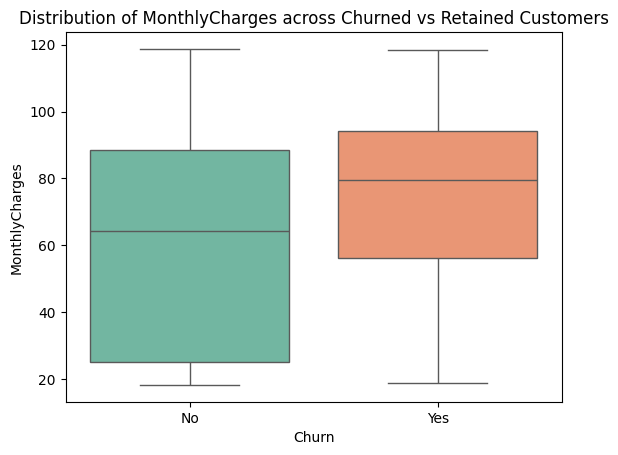

In [17]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", palette="Set2")
plt.title("Distribution of MonthlyCharges across Churned vs Retained Customers")
plt.show()

In [18]:
df.groupby("Churn")["MonthlyCharges"].agg(["mean", "median"])

,mean,median
Churn,,
No,61.265124,64.425
Yes,74.441332,79.650


> Median monthly charges high among customers who have churned

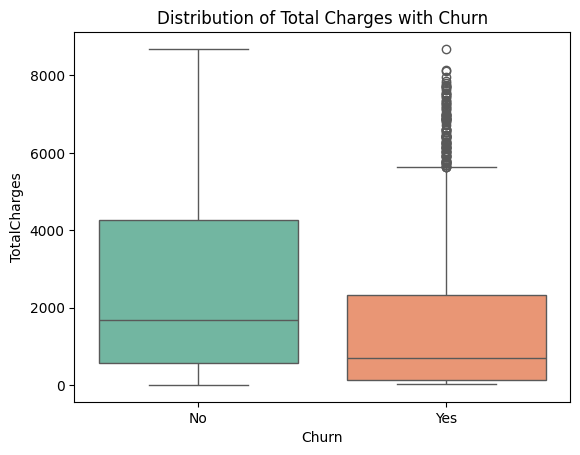

In [19]:
sns.boxplot(data=df, x="Churn", y="TotalCharges", palette="Set2")
plt.title("Distribution of Total Charges with Churn")
plt.show()

NOTES
---

> The median total charges is lower for churned customers compared to the customers who stayed.

total charges = tenure * monthly charges 

The lower median could be either due to fewer months spent with the monthly or cheaper monthly charges. 

Let's investigate the relationship between churn and tenure

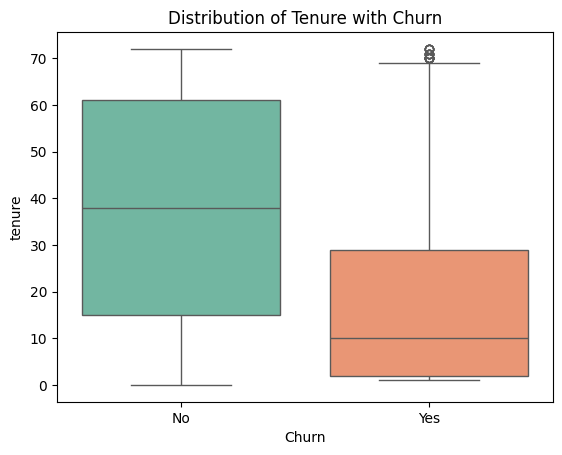

In [20]:
sns.boxplot(data=df, x="Churn", y="tenure", palette="Set2")
plt.title("Distribution of Tenure with Churn")
plt.show()

In [21]:
df.groupby("Churn")["tenure"].agg(["mean", "median"])

,mean,median
Churn,,
No,37.569965,38.0
Yes,17.979133,10.0


>  The median tenure of churned customers is sitting much lower compared to retained customers.

In [22]:
bins = [-1, 0, 1, 3, 6, 12, 24, 48, 72]

labels = [
    "0 months",
    "1 month",
    "2-3 months",
    "4-6 months",
    "7-12 months",
    "13-24 months",
    "25-48 months",
    "49-72 months",
]

df["tenure_band"] = pd.cut(df["tenure"], bins=bins, labels=labels)

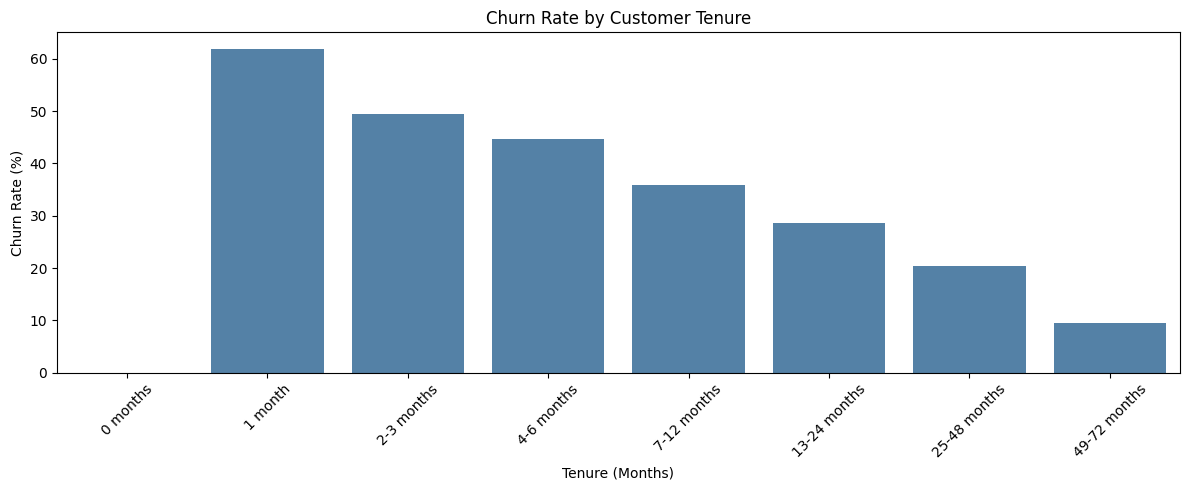

In [23]:
tenure_churn = (
    df.groupby("tenure_band", observed=True)
    .agg(
        Customers=("Churn", "size"),
        Churn_rate=("Churn", lambda x: (x == "Yes").mean() * 100),
    )
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.barplot(data=tenure_churn, x="tenure_band", y="Churn_rate", color="steelblue")

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [24]:
tenure_churn

,tenure_band,Customers,Churn_rate
0,0 months,11,0.000000
1,1 month,613,61.990212
2,2-3 months,438,49.543379
3,4-6 months,419,44.630072
4,7-12 months,705,35.886525
5,13-24 months,1024,28.710938
6,25-48 months,1594,20.388959
7,49-72 months,2239,9.513176


NOTES
---

Customer churn is strongly associated with tenure, with the highest observed churn proportion (61.99%) among customers recorded at one month. The proportion decreases consistently across longer-tenure groups, reaching approximately 9.51% among customers with 49–72 months of tenure. This identifies early-tenure customers as a potentially important segment for retention efforts.

In [25]:
tenure_1month = df[df["tenure_band"] == "1 month"]

In [26]:
tenure_1month.shape

(613, 22)

In [27]:
tenure_1month["Churn"].value_counts(normalize=True)

Churn
Yes    0.619902
No     0.380098
Name: proportion, dtype: float64

In [28]:
tenure_1month.loc[tenure_1month["Churn"] == "Yes", "Contract"].value_counts()

Contract
Month-to-month    380
Name: count, dtype: int64

In [29]:
pd.crosstab(
    tenure_1month["PaymentMethod"], tenure_1month["Churn"], normalize="index"
).mul(100).round(2)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),47.22,52.78
Credit card (automatic),63.33,36.67
Electronic check,23.79,76.21
Mailed check,49.81,50.19


In [30]:
tenure_1month.loc[tenure_1month["Churn"] == "Yes", "SeniorCitizen"].value_counts()

SeniorCitizen
0    306
1     74
Name: count, dtype: int64

NOTES
---
    
    * 100% of the customers who churned at 1 month were in month-to-month contract type.
    * Among customers recorded at one month of tenure, electronic-check users have a particularly high observed churn proportion.

## Let's test this hypothesis

Null hypothesis: The tenure distributions of churned and retained customers are identical.  

Alternative hypothesis: The tenure distributions of churned and retained customers differ.

We will use Mann-Whitney U test as the boxplot suggests skewness in the distributions of these groups of customers.

In [31]:
from scipy.stats import mannwhitneyu

tenure_churned = df.loc[df["Churn"] == "Yes", "tenure"]
tenure_retained = df.loc[df["Churn"] == "No", "tenure"]

In [32]:
stat, p_value = mannwhitneyu(tenure_churned, tenure_retained, alternative="two-sided")

print("U-stat:", stat)
print("P value:", p_value)

U-stat: 2515538.0
P value: 2.419635517951866e-208


> The p value is extremely small, the MannWhitneyU test shows that the tenure distributions differ significantly between churned and retained customers. So, we can reject the Null Hypothesis.

p_value does not inform us about the strength of this relationship. So, let's measure the effect size. 

In [33]:
n1 = len(tenure_churned)
n2 = len(tenure_retained)

rank_biserial = (2 * stat / (n1 * n2)) - 1
print("Rank biserial:", rank_biserial)

Rank biserial: -0.4797343510572577


## Tenure shows a moderately strong relationship with Churn

* The churned group is passed first, the negative value indicates that the churned customers has lower tenure compared to retained customers. Approx 0.5 here says the relationship has moderate strength.

TotalCharges is partly determined by tenure. 

## Let's test the relationship between Monthly charges and churn. 

Null Hypothesis: The Monthly Charges distribution is identical for churned and retained customers  

Alternative Hypothesis: The Monthly Charges distribution differs for these groups

We shall use MannWhitneyU test again as we are dealing with a cat variable and a numerical variable. 

In [34]:
mc_churned = df.loc[df["Churn"] == "Yes", "MonthlyCharges"]
mc_retained = df.loc[df["Churn"] == "No", "MonthlyCharges"]

stat, p_value = mannwhitneyu(mc_churned, mc_retained, alternative="two-sided")

print("U-stat:", stat)
print("p value:", p_value)

U-stat: 6003125.5
p value: 3.311627651988586e-54


> The p_value < 0.05. The ManWhitneyU test shows that the Monthly charges distributions significantly differ between churned and retained customers. So, we can reject the Null Hypothesis.

Let's quantify the strength of this relationship using Rank Biserial.

In [35]:
n1 = len(mc_churned)
n2 = len(mc_retained)

rank_biserial = (2 * stat / (n1 * n2)) - 1
print("Rank biserial:", rank_biserial)

Rank biserial: 0.24157137914125104




### This means churned customers tend to pay higher monthly charges.

But this doesn't establish that price alone causes the customers to leave. 

## So, what else could be driving the churn ? 

In [36]:
df["Contract"].value_counts(normalize=True)

Contract
Month-to-month    0.550192
Two year          0.240664
One year          0.209144
Name: proportion, dtype: float64

In [37]:
churn_by_contract = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
churn_by_contract

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


In [101]:
df.groupby("Contract")["MonthlyCharges"].agg(["count", "mean", "median", "min", "max"])

,count,mean,median,min,max
Contract,,,,,
Month-to-month,3875,66.398490,73.25,18.75,117.45
One year,1473,65.048608,68.75,18.25,118.60
Two year,1695,60.770413,64.35,18.40,118.75


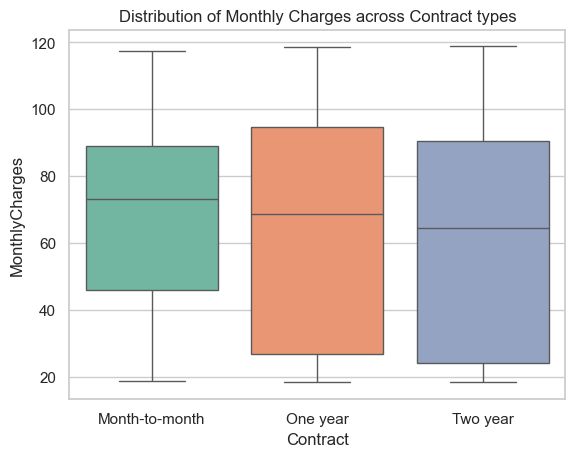

In [103]:
sns.boxplot(data=df, x="Contract", y="MonthlyCharges", palette="Set2")
plt.title("Distribution of Monthly Charges across Contract types")
plt.show()

> The median monthly charges of Month-to-month contract type is sitting highest, followed by One year contract and Two year contract

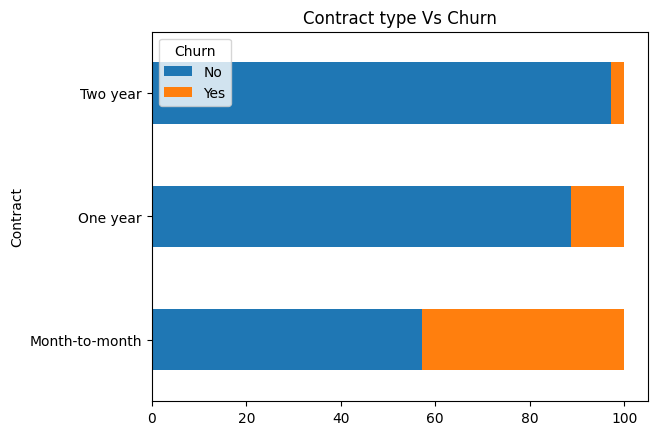

In [38]:
churn_by_contract.plot(kind="barh", stacked=True)
plt.title("Contract type Vs Churn")
plt.show()

> The crosstab suggests that % churned is low as the contract type gets longer

## Let's test this association to see if its statistically significant. 

Null Hypothesis: Contract type and Churn are independent  
Alternative Hypothesis: Contract type and Churn have an association

We will test this hypotheses using Chi-square test.

In [39]:
from scipy.stats import chi2_contingency

In [40]:
table = pd.crosstab(df["Contract"], df["Churn"])

chi2, p_val, dof, expected = chi2_contingency(table)

print("Chi2 stat:", chi2)
print("p_val:", p_val)
print("Deg of Freedom:", dof)

Chi2 stat: 1184.5965720837926
p_val: 5.863038300673393e-258
Deg of Freedom: 2


> Let's check the expected frequencies (how many customers should actually belong in these boxes to say Contract and Churn are independent)

In [41]:
pd.DataFrame(expected, index=table.index, columns=table.columns)

Churn,No,Yes
Contract,,
Month-to-month,2846.691751,1028.308249
One year,1082.110180,390.889820
Two year,1245.198069,449.801931


In [42]:
table

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


> We can see that the expected frequencies and what the actual data shows are very different

In [43]:
# Strength of the association using Cramers v (effect size)

n = table.to_numpy().sum()
r, c = table.shape

cramers_v = np.sqrt(chi2 / (n * min(r - 1, c - 1)))

print(f"Cramer's V: {cramers_v:.3f}")

Cramer's V: 0.410


## Contract and Churn shows a moderately strong association


> The p_value is extremely small, so we reject the Null Hypothesis. Chi2 test of independence shows that Contract and Churn do have an association. The strength of association was quantified using Cramer's V which yielded a value of 0.4 suggesting a moderate strength in association.  

## Does contract type provide additional information about churn after accounting for tenure?

In [44]:
# for all tenure
df.groupby("Contract")["Churn"].apply(lambda x: (x == "Yes").mean() * 100)

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64

In [45]:
# calculate churn rates for each contract type after restricting the customer base to 12-24mon tenure
df[df["tenure"].between(12, 24)].groupby("Contract")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

Contract
Month-to-month    37.788578
One year           9.589041
Two year           0.000000
Name: Churn, dtype: float64

In [46]:
df[df["tenure"].between(12, 24)].groupby("Contract")["Churn"].agg(
    customers="count", churned=lambda x: (x == "Yes").sum()
)

,customers,churned
Contract,,
Month-to-month,823,311
One year,219,21
Two year,99,0


* Month-to-month group still has high churn rate
* One year contract group have considerably lower churn
* Two year has no churn for this subset

This suggests that contract type is associated with churn even while comparing approximately similar tenure customers.
Tenure is a plausible confounding variable since we have observed an association with Contract (predictor) as well as our Target variable Churn.

## Gender, SeniorCitizen, Partner, "Dependents" Vs Churn

In [47]:
# Gender Vs Churn
pd.crosstab(df["gender"], df["Churn"], normalize="index")

Churn,No,Yes
gender,,
Female,0.730791,0.269209
Male,0.738397,0.261603


* The churn rate across genders appears to be balanced.

In [48]:
# SeniorCitizen Vs Churn
pd.crosstab(df["SeniorCitizen"], df["Churn"], normalize="index")

Churn,No,Yes
SeniorCitizen,,
0,0.763938,0.236062
1,0.583187,0.416813


In [49]:
df["SeniorCitizen"].value_counts(normalize=True)

SeniorCitizen
0    0.837853
1    0.162147
Name: proportion, dtype: float64

In [50]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

* Senior citizens have a higher churn rate than non-senior customers.

Let's verify if this relationship is statistically significant using chi2 test

In [51]:
table = pd.crosstab(df["SeniorCitizen"], df["Churn"])

chi2, p_value, dof, expected = chi2_contingency(table)

print(f"P-value: {p_value:.6g}")

P-value: 1.51007e-36


In [52]:
pd.DataFrame(expected, index=table.index, columns=table.columns)

Churn,No,Yes
SeniorCitizen,,
0,4335.052392,1565.947608
1,838.947608,303.052392


In [53]:
table

Churn,No,Yes
SeniorCitizen,,
0,4508,1393
1,666,476


In [54]:
n = table.to_numpy().sum()

phi = np.sqrt(chi2 / n)

print(f"Phi: {phi:.3f}")

Phi: 0.150


* Senior citizens exhibit a 42% churn rate compared to non-senior customers (23%). This relationship was tested using Chi2 test. Turns out that the association is statistically significant. However the effect size is small (Phi = 0.15 for this 2x2 table), showing a weak association only. 

In [55]:
pd.crosstab(df["Partner"], df["Churn"], normalize="index")

Churn,No,Yes
Partner,,
No,0.670420,0.329580
Yes,0.803351,0.196649


In [56]:
table = pd.crosstab(df["Partner"], df["Churn"])

chi2, p_value, dof, expected = chi2_contingency(table)

print(f"P-value: {p_value:.6g}")

P-value: 2.13991e-36


In [57]:
n = table.to_numpy().sum()
r, c = table.shape

cramers_v = np.sqrt(chi2 / (n * min(r - 1, c - 1)))

print(f"Cramer's V: {cramers_v:.3f}")

Cramer's V: 0.150


Between Partner and churn, there is statistical evidence that an association is present but the effect size is small. 

In [58]:
pd.crosstab(df["Dependents"], df["Churn"], normalize="index")

Churn,No,Yes
Dependents,,
No,0.687209,0.312791
Yes,0.845498,0.154502


In [59]:
table = pd.crosstab(df["Dependents"], df["Churn"])

chi2, p_value, dof, expected = chi2_contingency(table)

print(f"P-value: {p_value:.6g}")

P-value: 4.92492e-43


In [60]:
n = table.to_numpy().sum()
r, c = table.shape

cramers_v = np.sqrt(chi2 / (n * min(r - 1, c - 1)))

print(f"Cramer's V: {cramers_v:.3f}")

Cramer's V: 0.164


Between Dependents and churn, the association is present but the effect size is small.

In [61]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn',
       'tenure_band'],
      dtype='object')

In [62]:
df["PhoneService"].value_counts()

PhoneService
Yes    6361
No      682
Name: count, dtype: int64

In [63]:
plans = [
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "PaperlessBilling",
    "PaymentMethod",
]

In [64]:
for col in plans:
    print(df[col].value_counts(normalize=True))
    print("---" * 20)

PhoneService
Yes    0.903166
No     0.096834
Name: proportion, dtype: float64
------------------------------------------------------------
MultipleLines
No                  0.481329
Yes                 0.421837
No phone service    0.096834
Name: proportion, dtype: float64
------------------------------------------------------------
InternetService
Fiber optic    0.439585
DSL            0.343746
No             0.216669
Name: proportion, dtype: float64
------------------------------------------------------------
OnlineSecurity
No                     0.496663
Yes                    0.286668
No internet service    0.216669
Name: proportion, dtype: float64
------------------------------------------------------------
OnlineBackup
No                     0.438450
Yes                    0.344881
No internet service    0.216669
Name: proportion, dtype: float64
------------------------------------------------------------
DeviceProtection
No                     0.439443
Yes                    0.34

In [65]:
for col in plans:
    print(pd.crosstab(df[col], df["Churn"], normalize="index"))
    print("---" * 20)

Churn               No       Yes
PhoneService                    
No            0.750733  0.249267
Yes           0.732904  0.267096
------------------------------------------------------------
Churn                   No       Yes
MultipleLines                       
No                0.749558  0.250442
No phone service  0.750733  0.249267
Yes               0.713901  0.286099
------------------------------------------------------------
Churn                  No       Yes
InternetService                    
DSL              0.810409  0.189591
Fiber optic      0.581072  0.418928
No               0.925950  0.074050
------------------------------------------------------------
Churn                      No       Yes
OnlineSecurity                         
No                   0.582333  0.417667
No internet service  0.925950  0.074050
Yes                  0.853888  0.146112
------------------------------------------------------------
Churn                      No       Yes
OnlineBackup       

Notes
---

Hierarchical dependencies are seen between PhoneService and Multiple lines. The same is seen in InternetService and related add on features. The resulting multicollinearity will affect the inferential power of Logisitic Regression model, so use a clean feature set if you want to interpret the coefficients. 

Use original features for catboost. 

In [66]:
df.loc[df["PhoneService"] == "No", "InternetService"].value_counts()

InternetService
DSL    682
Name: count, dtype: int64

In [67]:
df.loc[df["PhoneService"] == "No", "Churn"].value_counts(normalize=True)

Churn
No     0.750733
Yes    0.249267
Name: proportion, dtype: float64

In [68]:
df.loc[df["InternetService"] == "No", "PhoneService"].value_counts()

PhoneService
Yes    1526
Name: count, dtype: int64

* customers without a Phone Service are DSL users
* customers without Internet service have a phone service. 

In [69]:
df.loc[df["InternetService"] == "No", "Churn"].value_counts(normalize=True)

Churn
No     0.92595
Yes    0.07405
Name: proportion, dtype: float64

In [70]:
pd.crosstab(df["InternetService"], df["Churn"])

Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


In [71]:
pd.crosstab(df["InternetService"], df["Churn"], normalize="index").mul(100).round(2)

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


* This table shows that the Churn rate is highest among Fiber optics users, followed by DSL. 

In [72]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn',
       'tenure_band'],
      dtype='object')

In [73]:
df["MultipleLines"].value_counts()

MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

In [74]:
pd.crosstab(df["MultipleLines"], df["Churn"], normalize="index").mul(100).round(2)

Churn,No,Yes
MultipleLines,,
No,74.96,25.04
No phone service,75.07,24.93
Yes,71.39,28.61


> The distribution of churned and retained customers across MultipleLines appear to overlap. 

## Let's check if the internet adds on have an association with Churn

In [75]:
addons = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
]

In [76]:
internet_df = df[df["InternetService"] != "No"]

In [77]:
for col in addons:
    print(f"\n{col}")

    churn_rates = pd.crosstab(internet_df[col], internet_df["Churn"], normalize="index")

    print(churn_rates["Yes"].round(3))


OnlineSecurity
OnlineSecurity
No     0.418
Yes    0.146
Name: Yes, dtype: float64

OnlineBackup
OnlineBackup
No     0.399
Yes    0.215
Name: Yes, dtype: float64

DeviceProtection
DeviceProtection
No     0.391
Yes    0.225
Name: Yes, dtype: float64

TechSupport
TechSupport
No     0.416
Yes    0.152
Name: Yes, dtype: float64

StreamingTV
StreamingTV
No     0.335
Yes    0.301
Name: Yes, dtype: float64

StreamingMovies
StreamingMovies
No     0.337
Yes    0.299
Name: Yes, dtype: float64


## Let's inspect if these internet add ons have an association with Churn

In [78]:
results = []

for col in addons:
    table = pd.crosstab(internet_df[col], internet_df["Churn"])

    chi2, p_value, dof, expected = chi2_contingency(table)

    phi = np.sqrt(chi2 / table.to_numpy().sum())

    results.append(
        {"Add-on": col, "P-value": p_value, "Phi": phi, "Min expected": expected.min()}
    )

results_df = pd.DataFrame(results)
results_df

,Add-on,P-value,Phi,Min expected
0,OnlineSecurity,2.410305e-96,0.280412,642.625340
1,OnlineBackup,7.418142e-48,0.195669,773.123799
2,DeviceProtection,2.302959e-39,0.176733,770.895777
3,TechSupport,4.351917e-92,0.274019,650.582563
4,StreamingTV,6.457992e-03,0.036668,861.608120
5,StreamingMovies,3.157402e-03,0.039743,869.565343


> We have significant statistical evidence that all the add-on features show association with churn. 

> Security and technical support subscriptions particularly have noticeably stronger associations with churn than entertainment add-ons. One possible explanation is that, customers who intend to stay longer avail these add ons. Another plausible explanation is be that these add ons make them stay longer. But we can't establish causality with these observations. 
> The streaming features have Phi values close to zero, suggesting that they exhibit a very weak association.


In [79]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn',
       'tenure_band'],
      dtype='object')

## Churn with Billing and Payment features

In [80]:
pd.crosstab(df["PaperlessBilling"], df["Churn"], normalize="index")

Churn,No,Yes
PaperlessBilling,,
No,0.836699,0.163301
Yes,0.664349,0.335651


> The churn rate appears to be double for customers who have paperless billing.
>
> Let's check if there is statistical evidence for this relationship.

In [81]:
table = pd.crosstab(df["PaperlessBilling"], df["Churn"])

chi2, p_value, dof, expected = chi2_contingency(table)

print("p_value:", p_value)

p_value: 4.0733546686659864e-58


> Let's quantify the strength of this association

In [82]:
pd.DataFrame(expected, index=table.index, columns=table.columns)

Churn,No,Yes
PaperlessBilling,,
No,2109.857731,762.142269
Yes,3064.142269,1106.857731


In [83]:
table

Churn,No,Yes
PaperlessBilling,,
No,2403,469
Yes,2771,1400


In [84]:
n = table.to_numpy().sum()
r, c = table.shape

cramers_v = np.sqrt(chi2 / (n * min(r - 1, c - 1)))

print(f"Cramer's V: {cramers_v:.3f}")

Cramer's V: 0.191


NOTES
---

* The p_value is extremely small. This shows that there is significant statistical evidence for an association between Paperless Billing and Churn rate. But the Cramer's V value of 0.191 the effect size of this association is weak/small. 

In [85]:
df["PaymentMethod"].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [86]:
pd.crosstab(df["PaymentMethod"], df["Churn"], normalize="index")

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),0.832902,0.167098
Credit card (automatic),0.847569,0.152431
Electronic check,0.547146,0.452854
Mailed check,0.808933,0.191067


* The churn rate appears to be highest for Electronic Check

Let's check if PaymentMethod has an association with Churn rate.

In [87]:
table = pd.crosstab(df["PaymentMethod"], df["Churn"])

chi2, p_value, dof, expected = chi2_contingency(table)

n = table.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n * min(table.shape[0] - 1, table.shape[1] - 1)))

print("P-value:", p_value)
print("Cramer's V:", cramers_v)

P-value: 3.6823546520098007e-140
Cramer's V: 0.30335862555407056


> There is significant statistical evidence that PaymentMethod has an association with Churn rate.
> Cramer's V value of 0.3 shows that the association is of moderate strength.

* Let's check if "Electronic check" in particular shows a much stronger association

In [88]:
df["ElectronicCheck"] = df["PaymentMethod"].eq("Electronic check")

pd.crosstab(df["ElectronicCheck"], df["Churn"], normalize="index").mul(100).round(2)

Churn,No,Yes
ElectronicCheck,,
False,82.94,17.06
True,54.71,45.29


In [89]:
table = pd.crosstab(df["ElectronicCheck"], df["Churn"])

chi2, p_value, dof, expected = chi2_contingency(table)

n = table.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n * min(table.shape[0] - 1, table.shape[1] - 1)))

print("P-value:", p_value)
print("Cramer's V:", cramers_v)

P-value: 2.5280301640753998e-141
Cramer's V: 0.30157829053700946


In [90]:
op = df[df["PaymentMethod"] != "Electronic check"]

In [91]:
pd.crosstab(op["PaymentMethod"], op["Churn"], normalize="index").mul(100).round(2)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Mailed check,80.89,19.11


In [92]:
table = pd.crosstab(op["PaymentMethod"], op["Churn"])

chi2, p_value, dof, expected = chi2_contingency(table)

n = table.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n * min(table.shape[0] - 1, table.shape[1] - 1)))

print("P-value:", p_value)
print("Cramer's V:", cramers_v)

P-value: 0.01457037311645627
Cramer's V: 0.042519844475795245


NOTES
---

* Excluded Electronic check customers and tested the association with churn. The p_value shows statistical significance, however Cramer's V shows a very weak, almost neglible association.
* This confirms that Electronic check customers stand out.
* The overall association between PaymentMethod and Churn appears to be driven predominantly by "Electronic check" customers

## Could PaymentMethod and PaperlessBilling be associated with eachother?

In [93]:
pd.crosstab(df["PaymentMethod"], df["PaperlessBilling"], normalize="index").mul(
    100
).round(2)

PaperlessBilling,No,Yes
PaymentMethod,,
Bank transfer (automatic),42.29,57.71
Credit card (automatic),42.05,57.95
Electronic check,26.34,73.66
Mailed check,59.31,40.69


In [94]:
table = pd.crosstab(df["PaymentMethod"], df["PaperlessBilling"])

chi2, p_value, dof, expected = chi2_contingency(table)

n = table.to_numpy().sum()

cramers_v = np.sqrt(chi2 / (n * min(table.shape[0] - 1, table.shape[1] - 1)))

print("P-value:", p_value)
print("Cramér's V:", cramers_v)

P-value: 4.1152390707103177e-94
Cramér's V: 0.2487185726719847


> The association is statistically significant but the effect size is modest to moderate.


## Do electronic-check customers continue to show higher churn rates within both paperless-billing groups?

In [95]:
pd.crosstab(
    [df["PaymentMethod"].eq("Electronic check"), df["PaperlessBilling"]],
    df["Churn"],
    normalize="index",
).mul(100).round(2)

Churn                              No    Yes
PaymentMethod PaperlessBilling              
False         No                88.22  11.78
              Yes               78.06  21.94
True          No                67.26  32.74
              Yes               50.23  49.77

In [96]:
pd.crosstab(
    [df["PaymentMethod"].eq("Electronic check"), df["PaperlessBilling"]], df["Churn"]
)

Churn                             No  Yes
PaymentMethod PaperlessBilling           
False         No                1984  265
              Yes               1896  533
True          No                 419  204
              Yes                875  867

* Electronic check users consistently have higher churns (33% and 50%) within the paperless billing groups.
* Paperless billing is associated with higher churns within both payment groups (22% and 50%)
* This means electronic check users is associated to churn even after stratifying paperless billing. 

But I will interpret this association with caution as there maybe other confounding variables. 

## Key EDA Findings: Visual Summary

The following visualizations consolidate the most notable
patterns identified during exploratory analysis.

These findings represent observed associations rather than
causal relationships or validated intervention effects.

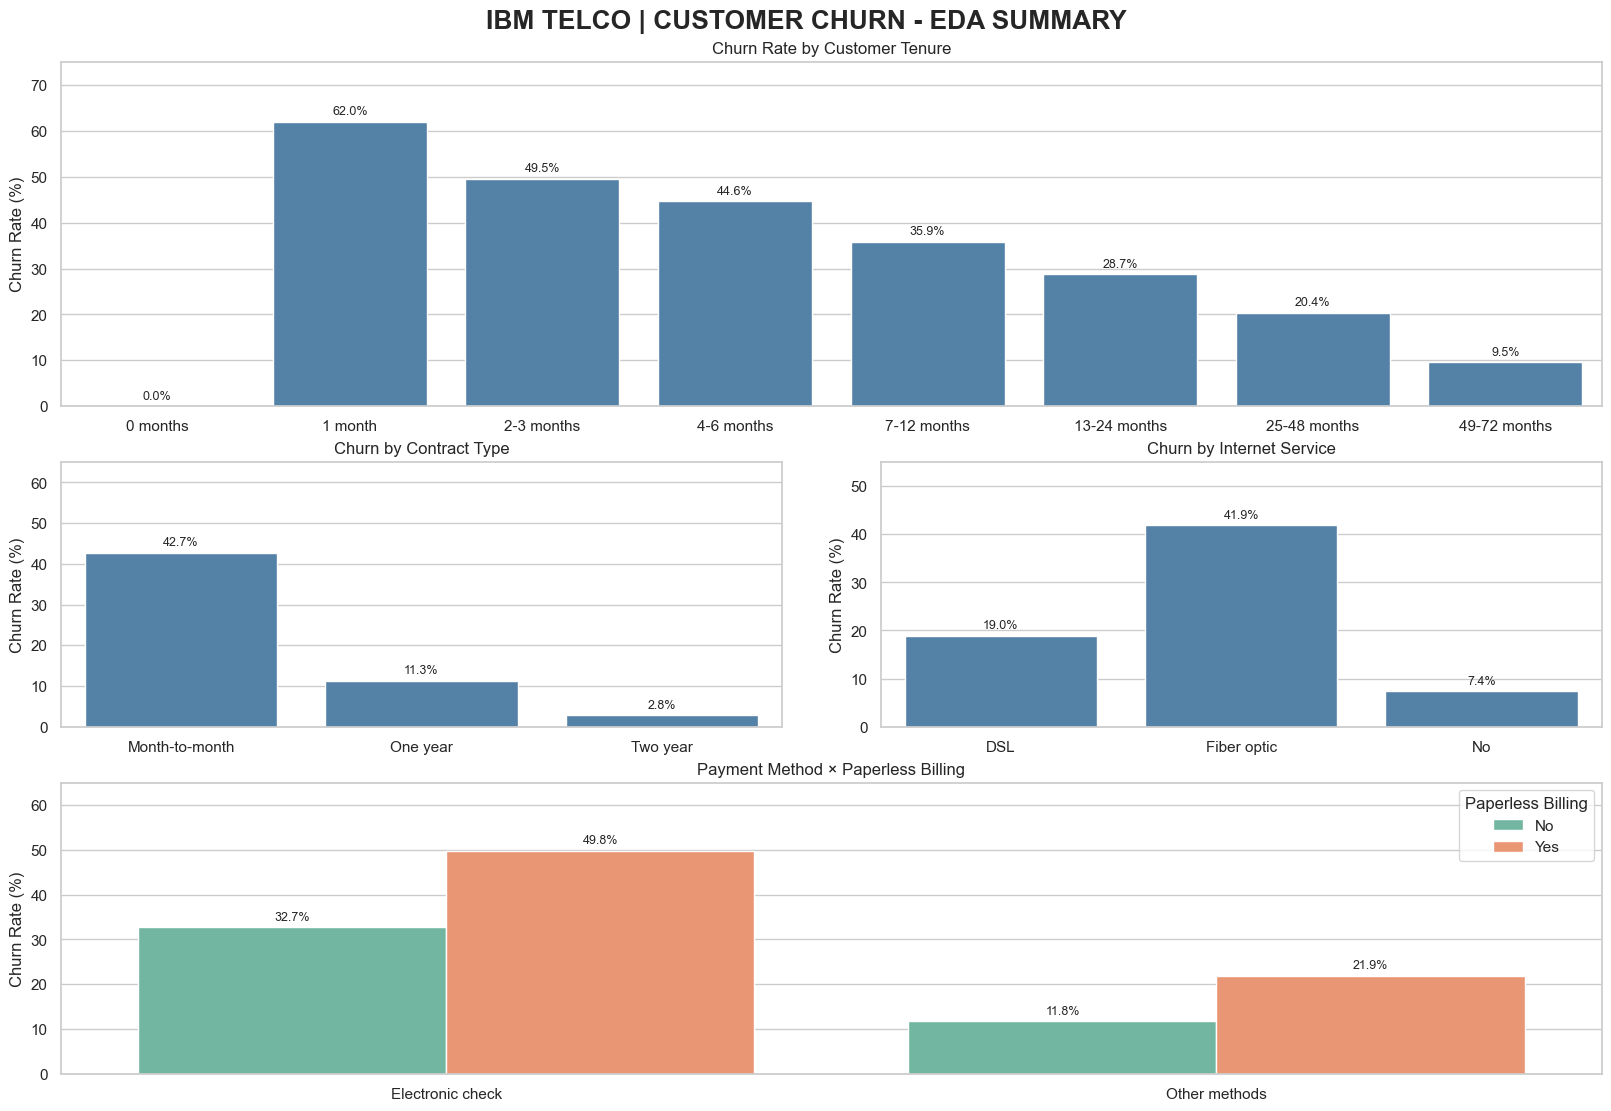

In [99]:
from matplotlib.gridspec import GridSpec

sns.set_theme(style="whitegrid")

fig = plt.figure(figsize=(16, 11), constrained_layout=True)

gs = GridSpec(3, 2, figure=fig, height_ratios=[1.3, 1, 1.1])

ax1 = fig.add_subplot(gs[0, :])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[1, 1])
ax4 = fig.add_subplot(gs[2, :])


# Helper for percentage labels
def add_labels(ax):
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)


# 1. TENURE
tenure_summary = (
    df.groupby("tenure_band", observed=True)
    .agg(
        Customers=("Churn", "size"),
        ChurnRate=("Churn", lambda x: x.eq("Yes").mean() * 100),
    )
    .reset_index()
)

sns.barplot(
    data=tenure_summary, x="tenure_band", y="ChurnRate", color="steelblue", ax=ax1
)

add_labels(ax1)
ax1.set_title("Churn Rate by Customer Tenure")
ax1.set_xlabel("")
ax1.set_ylabel("Churn Rate (%)")
ax1.tick_params(axis="x", rotation=0)
ax1.set_ylim(0, 75)

# 2. CONTRACT
contract = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: x.eq("Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

sns.barplot(data=contract, x="Contract", y="ChurnRate", color="steelblue", ax=ax2)

add_labels(ax2)
ax2.set_title("Churn by Contract Type")
ax2.set_xlabel("")
ax2.set_ylabel("Churn Rate (%)")
ax2.set_ylim(0, 65)
ax2.tick_params(axis="x", rotation=0)

# 3. INTERNET SERVICE
internet = (
    df.groupby("InternetService")["Churn"]
    .apply(lambda x: x.eq("Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

sns.barplot(
    data=internet, x="InternetService", y="ChurnRate", color="steelblue", ax=ax3
)

add_labels(ax3)
ax3.set_title("Churn by Internet Service")
ax3.set_xlabel("")
ax3.set_ylabel("Churn Rate (%)")
ax3.set_ylim(0, 55)

# 4. PAYMENT + PAPERLESS BILLING
billing = df.copy()

billing["PaymentGroup"] = np.where(
    billing["PaymentMethod"].eq("Electronic check"), "Electronic check", "Other methods"
)

billing_summary = (
    billing.groupby(["PaymentGroup", "PaperlessBilling"])["Churn"]
    .apply(lambda x: x.eq("Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

sns.barplot(
    data=billing_summary,
    x="PaymentGroup",
    y="ChurnRate",
    hue="PaperlessBilling",
    palette="Set2",
    ax=ax4,
)

add_labels(ax4)
ax4.set_title("Payment Method × Paperless Billing")
ax4.set_xlabel("")
ax4.set_ylabel("Churn Rate (%)")
ax4.set_ylim(0, 65)
ax4.legend(title="Paperless Billing")

fig.suptitle("IBM TELCO | CUSTOMER CHURN - EDA SUMMARY", fontsize=19, fontweight="bold")

plt.savefig("eda_summary_dashboard.png", dpi=200, bbox_inches="tight")

plt.show()

## EDA: Key Findings and Business Interpretation

Customer churn appears to be closely associated with **tenure, contract type, monthly charges, internet service, and billing preferences**.

Customers who churn tend to have significantly shorter tenure, suggesting that churn is concentrated among relatively newer customers. Although churned customers generally pay higher monthly charges, their accumulated total charges are lower, likely because they have spent fewer months with the company. Customer churn is strongly associated with tenure, with the highest observed churn proportion (61.99%) among customers recorded at one month. The proportion decreases consistently across longer-tenure groups, reaching approximately 9.51% among customers with 49–72 months of tenure. This identifies early-tenure customers as a potentially important segment for retention efforts.

**Contract type shows a moderately strong association with churn.** Month-to-month customers exhibit considerably higher churn rates than customers on longer-term contracts. This pattern persists even within the 12–24 month tenure group, suggesting that contract type may provide additional information beyond tenure.

**Fiber-optic customers exhibit the highest churn rate (41.89%)**, compared with DSL customers (18.96%) and customers without internet service (7.40%). This raises questions about pricing, customer expectations, and service experience, although the dataset does not establish the underlying reasons.

Among internet subscribers, **online security and technical support show stronger associations with churn than entertainment add-ons**. Customers subscribing to security and support services have substantially lower observed churn rates. One possibility is that these services encourage retention; alternatively, customers who already intend to stay longer may be more likely to purchase them.

**Billing preferences reveal another notable pattern.** Electronic-check customers have considerably higher churn rates than customers using other payment methods. When electronic-check users are excluded, the association between payment method and churn becomes negligible in magnitude. Electronic-check customers also exhibit higher churn regardless of paperless-billing status, with the highest observed churn rate (49.77%) among customers using both electronic checks and paperless billing.

Senior citizens also exhibit higher churn rates than non-senior customers (41.7% versus 23.6%), although the overall association is relatively weak.

### Overall Interpretation

Churn does not appear to be associated with a single customer characteristic. Instead, the findings suggest that **customer lifecycle, contractual commitments, service subscriptions, and billing arrangements are all relevant to understanding churn behaviour**.

Several features may also contain overlapping information. Further investigation during predictive modelling will help determine which features contribute additional predictive value.

These findings are observational and should not be interpreted as evidence that changing contracts, payment methods, or add-on subscriptions would directly reduce churn.